In [1]:
import torch

import torch.utils.data

import pandas as pd
import scanpy as sc
import squidpy as sq

from pathlib import Path

from gctsvg import visualization
from gctsvg.preprocessing import common, singlecell, st, kidneycancer
from gctsvg.model.classifier import ClassifierDriver
from gctsvg.model.decomposer import DecomposerDriver

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
patient_id='PD47171'

In [3]:
# read ST data
adata_st = sc.read(data_dir / 'visium_merge_inter_upload.h5ad')
adata_st.var_names_make_unique()

# read scRNA data
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')
adata_sc.var_names_make_unique()

In [4]:
# Extract patient data
adata_st = kidneycancer.extract_st_patient_data(adata_st, patient_id)
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)

# extract cell type information
cell_types, n_classes = singlecell.get_cell_types(adata_sc)

In [5]:
# Format data to use ENSEMBL gene id as index
# necessary to align indexes of st and sc datasets
adata_sc = common.use_ensembl_gene_ids(adata_sc, 'name')

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [6]:
adata_sc.obs['broad_type'].values.categories.to_list()

['B-cell',
 'EC',
 'Epi_non-PT',
 'Epi_PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

In [7]:
adata_sc.obs

,orig.ident,nCount_RNA,nFeature_RNA,patient,percent.mt,summaryDescription,annotation,region,broad_type
5739STDY9266968_AACTGGTGTCTCCACT-1,5739STDY9266968,3598.0,1206,PD47171,7.254030,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_AGGGAGTGTCCGCTGA-1,5739STDY9266968,3447.0,1298,PD47171,5.686104,Tumour,Activated_B-RHOB,a,B-cell
5739STDY9266968_CATCGGGGTAAGGATT-1,5739STDY9266968,4602.0,601,PD47171,1.564537,Tumour,Plasma-IgA,a,Plasma
5739STDY9266968_CCACCTACAGCCTGTG-1,5739STDY9266968,3830.0,1854,PD47171,4.699739,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_CCACTACGTAGCGCAA-1,5739STDY9266968,3633.0,1427,PD47171,4.266446,Tumour,Activated_B-AREG,a,B-cell
...,...,...,...,...,...,...,...,...,...
5739STDY9266973_TTGTAGGTCCGCGTTT-1,5739STDY9266973,3627.0,1431,PD47171,11.524676,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTATGCGTGTGACCC-1,5739STDY9266973,3598.0,1235,PD47171,15.953307,Tumour-normal,Stress,g,RCC
5739STDY9266973_TTTGGTTAGCGACGTA-1,5739STDY9266973,3809.0,1519,PD47171,10.028879,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTGTCATCTATCCTA-1,5739STDY9266973,3901.0,1537,PD47171,5.229428,Tumour-normal,EMT,g,RCC


In [8]:
adata_st.var

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499411,mean_counts-6800STDY12499411,log1p_mean_counts-6800STDY12499411,pct_dropout_by_counts-6800STDY12499411,total_counts-6800STDY12499411,log1p_total_counts-6800STDY12499411
ENSEMBL,,,,,,,,,,
ENSG00000243485,Gene Expression,GRCh38,MIR1302-2HG,False,0,0.000000,0.000000,100.000000,0.0,0.000000
ENSG00000237613,Gene Expression,GRCh38,FAM138A,False,0,0.000000,0.000000,100.000000,0.0,0.000000
ENSG00000186092,Gene Expression,GRCh38,OR4F5,False,0,0.000000,0.000000,100.000000,0.0,0.000000
ENSG00000238009,Gene Expression,GRCh38,AL627309.1,False,6,0.002930,0.002925,99.707031,6.0,1.945910
ENSG00000239945,Gene Expression,GRCh38,AL627309.3,False,0,0.000000,0.000000,100.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...
ENSG00000277836,Gene Expression,GRCh38,AC141272.1,False,0,0.000000,0.000000,100.000000,0.0,0.000000
ENSG00000278633,Gene Expression,GRCh38,AC023491.2,False,0,0.000000,0.000000,100.000000,0.0,0.000000
ENSG00000276017,Gene Expression,GRCh38,AC007325.1,False,1,0.000488,0.000488,99.951172,1.0,0.693147


In [9]:
# print(adata_st.var.index[adata_st.var.index.duplicated()])
print(adata_st.var[adata_st.var.index.duplicated(keep=False)])

Empty DataFrame
Columns: [feature_types, genome, SYMBOL, mt, n_cells_by_counts-6800STDY12499411, mean_counts-6800STDY12499411, log1p_mean_counts-6800STDY12499411, pct_dropout_by_counts-6800STDY12499411, total_counts-6800STDY12499411, log1p_total_counts-6800STDY12499411]
Index: []


In [10]:
print(adata_st.n_vars)
print(adata_st.var.index.is_unique)
print(adata_sc.n_vars)
print(adata_sc.var.index.is_unique)

36601
True
18356
True


In [11]:
common.compute_hvgs(adata_sc)
common.compute_hvgs(adata_st)

# get feature matrices from st and sc data
geneset = common.get_common_geneset(adata_st, adata_sc)
adata_st = adata_st[:, geneset]
adata_sc = adata_sc[:, geneset]

n_feats = len(geneset)

Number of overlap genes: 896


In [12]:
# preprocess st and sc data
sc_target_sum = 1e3
sc_max = 10

common.preprocess(adata_st, sc_target_sum, sc_max)
common.preprocess(adata_sc, sc_target_sum, sc_max)

/workspace/ct-SVG/gctsvg/preprocessing/common.py:14: ImplicitModificationWarning: Setting element `.layers['original']` of view, initializing view as actual.
  adata.layers['original'] = adata.X.copy()
/workspace/ct-SVG/gctsvg/preprocessing/common.py:14: ImplicitModificationWarning: Setting element `.layers['original']` of view, initializing view as actual.
  adata.layers['original'] = adata.X.copy()


In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
centroids = singlecell.get_cell_type_centroids(adata_sc, geneset, device=device)

X_st = common.get_feature_matrix(adata_st)
dataset_sc = singlecell.create_classifier_dataset(adata_sc, device=device)
dtype=dataset_sc[0][0].dtype

std = adata_sc.var['std']
sc_std = torch.tensor(std.values, device=device)
# build graph from st adjacency

<class 'numpy.ndarray'>


In [14]:
geneset

Index(['ENSG00000186827', 'ENSG00000187017', 'ENSG00000049249',
       'ENSG00000142583', 'ENSG00000162444', 'ENSG00000028137',
       'ENSG00000162493', 'ENSG00000162460', 'ENSG00000162551',
       'ENSG00000173372',
       ...
       'ENSG00000078596', 'ENSG00000165376', 'ENSG00000101856',
       'ENSG00000183918', 'ENSG00000122121', 'ENSG00000022267',
       'ENSG00000029993', 'ENSG00000130822', 'ENSG00000198804',
       'ENSG00000228253'],
      dtype='object', name='ENSEMBL', length=896)

In [15]:
cell_types

['B-cell',
 'EC',
 'Epi_non-PT',
 'Epi_PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

In [16]:
n_classes

12

In [17]:
n_feats

896

In [18]:
# dataset = singlecell.create_classifier_dataset(adata_sc, device=device)
dataset_sc

In [19]:
dataset_sc[2][0].shape, dataset_sc[2][1].shape

(torch.Size([896]), torch.Size([]))

In [20]:
dataset_sc[0][1].dtype

torch.int64

In [21]:
driver = ClassifierDriver(n_feats, n_classes, device=device, dtype=dtype)

In [22]:
num_epochs=800
batch_size=4096

In [23]:
adata_sc.X

<Compressed Sparse Column sparse matrix of dtype 'float64'
	with 3330778 stored elements and shape (36110, 896)>

In [24]:
losses = driver.train(dataset_sc, num_epochs, batch_size)

Classifier already trained. Skipping...


In [25]:
classifier = driver.get_classifier()

In [26]:
if losses is not None:
    visualization.show_training_curve(range(1,num_epochs + 1), [losses], ["training loss"])

In [27]:
classifier

Classifier(
  (backbone_fc): Sequential(
    (0): Linear(in_features=896, out_features=675, bias=True)
    (1): BatchNorm1d(675, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): PReLU(num_parameters=675)
    (3): Linear(in_features=675, out_features=454, bias=True)
    (4): BatchNorm1d(454, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): PReLU(num_parameters=454)
    (6): Linear(in_features=454, out_features=233, bias=True)
    (7): BatchNorm1d(233, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): PReLU(num_parameters=233)
  )
  (out_fc): Linear(in_features=233, out_features=12, bias=True)
)

In [28]:
dataset_st = st.create_graph_data(adata_st, device=device, layer='original')

In [29]:
decomposer_driver = DecomposerDriver(adata_st.n_obs, adata_st.n_vars, n_classes, centroids, classifier, 
                                     sc_target_sum, sc_std, sc_max,
                                     device, dtype,
                                     alpha=1, beta=1, gamma=1)

In [30]:
adata_st

AnnData object with n_obs × n_vars = 2048 × 896
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial'
    layers: 'original'

In [31]:
num_epochs = 4000

In [32]:
total, recon, prior, spatial = decomposer_driver.fit(dataset_st, num_epochs)

  0%|          | 0/4000 [00:00<?, ?it/s]

In [33]:
# total, recon, prior, spatial

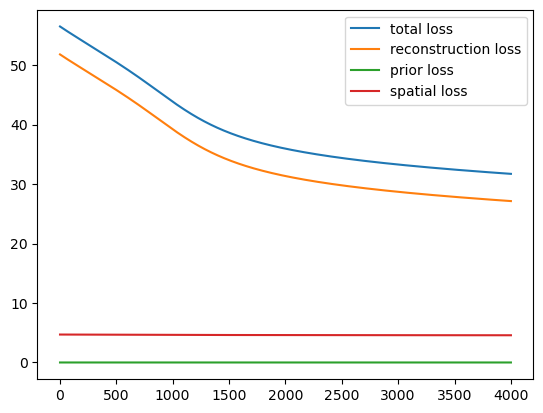

In [34]:
visualization.show_training_curve(range(1, num_epochs + 1), [total, recon, prior, spatial], ["total loss", "reconstruction loss", "prior loss", "spatial loss"])

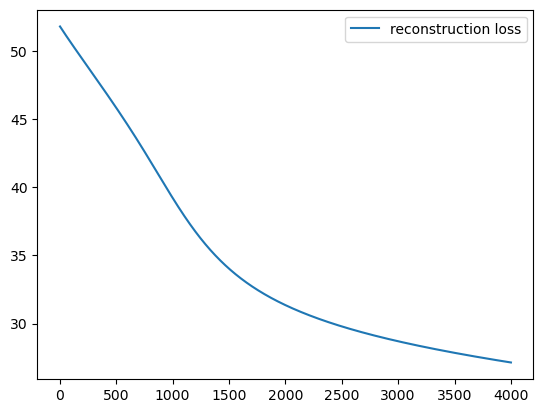

In [35]:
visualization.show_training_curve(range(1, num_epochs + 1), [recon], ["reconstruction loss"])

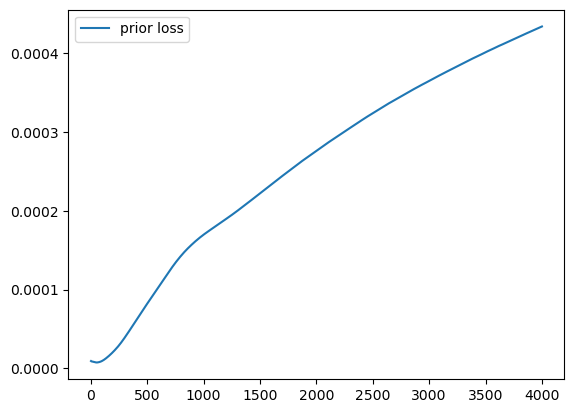

In [36]:
visualization.show_training_curve(range(1, num_epochs + 1), [prior], ["prior loss"])

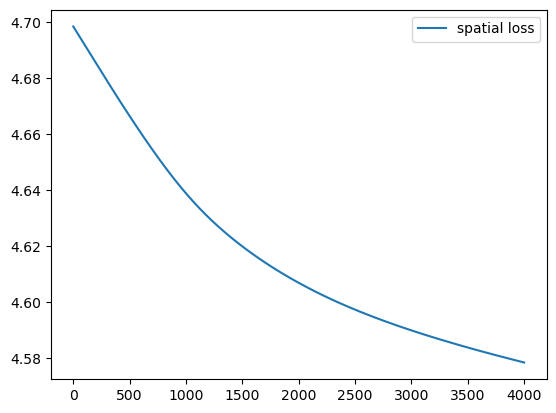

In [37]:
visualization.show_training_curve(range(1, num_epochs + 1), [spatial], ["spatial loss"])

In [38]:
# build proportions table
expression, proportions, reconstruction = decomposer_driver.get_decomposition()

In [39]:
proportions = proportions.cpu().detach().numpy()

In [40]:
adata_st.obs_names

Index(['6800STDY12499411_AAACAAGTATCTCCCA-1',
       '6800STDY12499411_AAACACCAATAACTGC-1',
       '6800STDY12499411_AAACATGGTGAGAGGA-1',
       '6800STDY12499411_AAACCGGGTAGGTACC-1',
       '6800STDY12499411_AAACCGTTCGTCCAGG-1',
       '6800STDY12499411_AAACGAAGATGGAGTA-1',
       '6800STDY12499411_AAACGAGACGGTTGAT-1',
       '6800STDY12499411_AAACTCGTGATATAAG-1',
       '6800STDY12499411_AAACTGCTGGCTCCAA-1',
       '6800STDY12499411_AAACTTAATTGCACGC-1',
       ...
       '6800STDY12499411_TTGTGCGGAAGCGGAT-1',
       '6800STDY12499411_TTGTGGCCCTGACAGT-1',
       '6800STDY12499411_TTGTGGTAGGAGGGAT-1',
       '6800STDY12499411_TTGTGTATGCCACCAA-1',
       '6800STDY12499411_TTGTGTTTCCCGAAAG-1',
       '6800STDY12499411_TTGTTCAGTGTGCTAC-1',
       '6800STDY12499411_TTGTTGTGTGTCAAGA-1',
       '6800STDY12499411_TTGTTTCACATCCAGG-1',
       '6800STDY12499411_TTGTTTCATTAGTCTA-1',
       '6800STDY12499411_TTGTTTCCATACAACT-1'],
      dtype='object', name='spot_id', length=2048)

In [41]:
cell_types

['B-cell',
 'EC',
 'Epi_non-PT',
 'Epi_PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

In [42]:
props = pd.DataFrame(proportions, index=adata_st.obs_names, columns=cell_types)
props = props.add_prefix("props_")

In [43]:
props

,props_B-cell,props_EC,props_Epi_non-PT,props_Epi_PT,props_Fibro,props_Mast,props_Myeloid,props_NK,props_Plasma,props_RCC,props_T-cell,props_pDC
spot_id,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.008488,0.003769,0.003860,0.003684,0.004885,0.002675,0.753054,0.004977,0.006301,0.200409,0.004247,0.003652
6800STDY12499411_AAACACCAATAACTGC-1,0.003655,0.271830,0.288281,0.017793,0.016695,0.015008,0.006737,0.160239,0.008274,0.024387,0.184367,0.002734
6800STDY12499411_AAACATGGTGAGAGGA-1,0.003573,0.002804,0.886058,0.009143,0.002797,0.005057,0.006901,0.006748,0.006552,0.063227,0.003092,0.004048
6800STDY12499411_AAACCGGGTAGGTACC-1,0.002692,0.223379,0.024133,0.028046,0.049285,0.002929,0.004975,0.010588,0.017545,0.358082,0.276666,0.001681
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.002719,0.269713,0.022095,0.010174,0.047979,0.011401,0.005031,0.185162,0.009862,0.007305,0.426128,0.002431
...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.001996,0.002669,0.003019,0.069273,0.004119,0.002716,0.282389,0.003772,0.006256,0.618047,0.003457,0.002286
6800STDY12499411_TTGTTGTGTGTCAAGA-1,0.006159,0.004348,0.005811,0.008669,0.005897,0.003494,0.665165,0.006239,0.007406,0.277493,0.004957,0.004362
6800STDY12499411_TTGTTTCACATCCAGG-1,0.002529,0.222541,0.010027,0.030783,0.054429,0.014942,0.004854,0.126371,0.007606,0.005207,0.517695,0.003016


In [44]:
props.columns

Index(['props_B-cell', 'props_EC', 'props_Epi_non-PT', 'props_Epi_PT',
       'props_Fibro', 'props_Mast', 'props_Myeloid', 'props_NK',
       'props_Plasma', 'props_RCC', 'props_T-cell', 'props_pDC'],
      dtype='object')

In [45]:
adata_st.obs[props.columns] = props

In [46]:
adata_st.obs

,in_tissue,array_row,array_col,sample,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,...,props_Epi_non-PT,props_Epi_PT,props_Fibro,props_Mast,props_Myeloid,props_NK,props_Plasma,props_RCC,props_T-cell,props_pDC
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,1,50,102,6800STDY12499411,4778,8.471987,14815.0,9.603463,27.046912,35.227810,...,0.003860,0.003684,0.004885,0.002675,0.753054,0.004977,0.006301,0.200409,0.004247,0.003652
6800STDY12499411_AAACACCAATAACTGC-1,1,59,19,6800STDY12499411,1536,7.337588,2822.0,7.945555,27.250177,36.463501,...,0.288281,0.017793,0.016695,0.015008,0.006737,0.160239,0.008274,0.024387,0.184367,0.002734
6800STDY12499411_AAACATGGTGAGAGGA-1,1,62,0,6800STDY12499411,2243,7.716015,4582.0,8.430109,28.000873,35.050196,...,0.886058,0.009143,0.002797,0.005057,0.006901,0.006748,0.006552,0.063227,0.003092,0.004048
6800STDY12499411_AAACCGGGTAGGTACC-1,1,42,28,6800STDY12499411,2555,7.846199,4903.0,8.497807,19.620640,28.696716,...,0.024133,0.028046,0.049285,0.002929,0.004975,0.010588,0.017545,0.358082,0.276666,0.001681
6800STDY12499411_AAACCGTTCGTCCAGG-1,1,52,42,6800STDY12499411,1277,7.153052,2113.0,7.656337,22.432560,32.465689,...,0.022095,0.010174,0.047979,0.011401,0.005031,0.185162,0.009862,0.007305,0.426128,0.002431
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,1,24,64,6800STDY12499411,3235,8.082093,8386.0,9.034438,25.518722,36.358216,...,0.003019,0.069273,0.004119,0.002716,0.282389,0.003772,0.006256,0.618047,0.003457,0.002286
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1,31,77,6800STDY12499411,4374,8.383662,12266.0,9.414668,22.215881,31.664764,...,0.005811,0.008669,0.005897,0.003494,0.665165,0.006239,0.007406,0.277493,0.004957,0.004362
6800STDY12499411_TTGTTTCACATCCAGG-1,1,58,42,6800STDY12499411,1328,7.192182,2317.0,7.748460,23.910229,34.570565,...,0.010027,0.030783,0.054429,0.014942,0.004854,0.126371,0.007606,0.005207,0.517695,0.003016


In [47]:
import numpy as np
import matplotlib.pyplot as plt
def display_cell_proportions(adata, cell_types, ncols=4):
    num_cell_types = len(cell_types)
    nrows = num_cell_types // ncols + (0 if num_cell_types % ncols == 0 else 1)

    columns = [f"props_{cell_type}" for cell_type in cell_types]
    values = adata.obs[columns].to_numpy()
    # vmin = np.min(values)
    # vmax = np.max(values)
   
    fig, axs = plt.subplots(nrows, ncols)
    for cell_type, ax in zip(columns, axs.flat):
        sq.pl.spatial_scatter(adata, 
                              color=cell_type,
                              fig=fig,
                              ax=ax,
                              # vmin=vmin, 
                              # vmax=vmax, 
                              colorbar=True,
                              title=cell_type,
                              figsize=6,
                              axis_label="")


    # print(axs)
    # print(axs.ravel())
    # sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=vmin, vmax=vmax))
    # cbar = fig.colorbar(sm, ax=axs.ravel().tolist())
    # cbar.set_label('Cell Type Proportion')
    fig.suptitle=('Cell Deconvolution')
    fig.set_size_inches(10,8)
    # print(fig.axes)
    plt.tight_layout()
    plt.show()

In [48]:
cell_types

['B-cell',
 'EC',
 'Epi_non-PT',
 'Epi_PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

/tmp/ipykernel_144010/2913716360.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_st, cmap='magma',


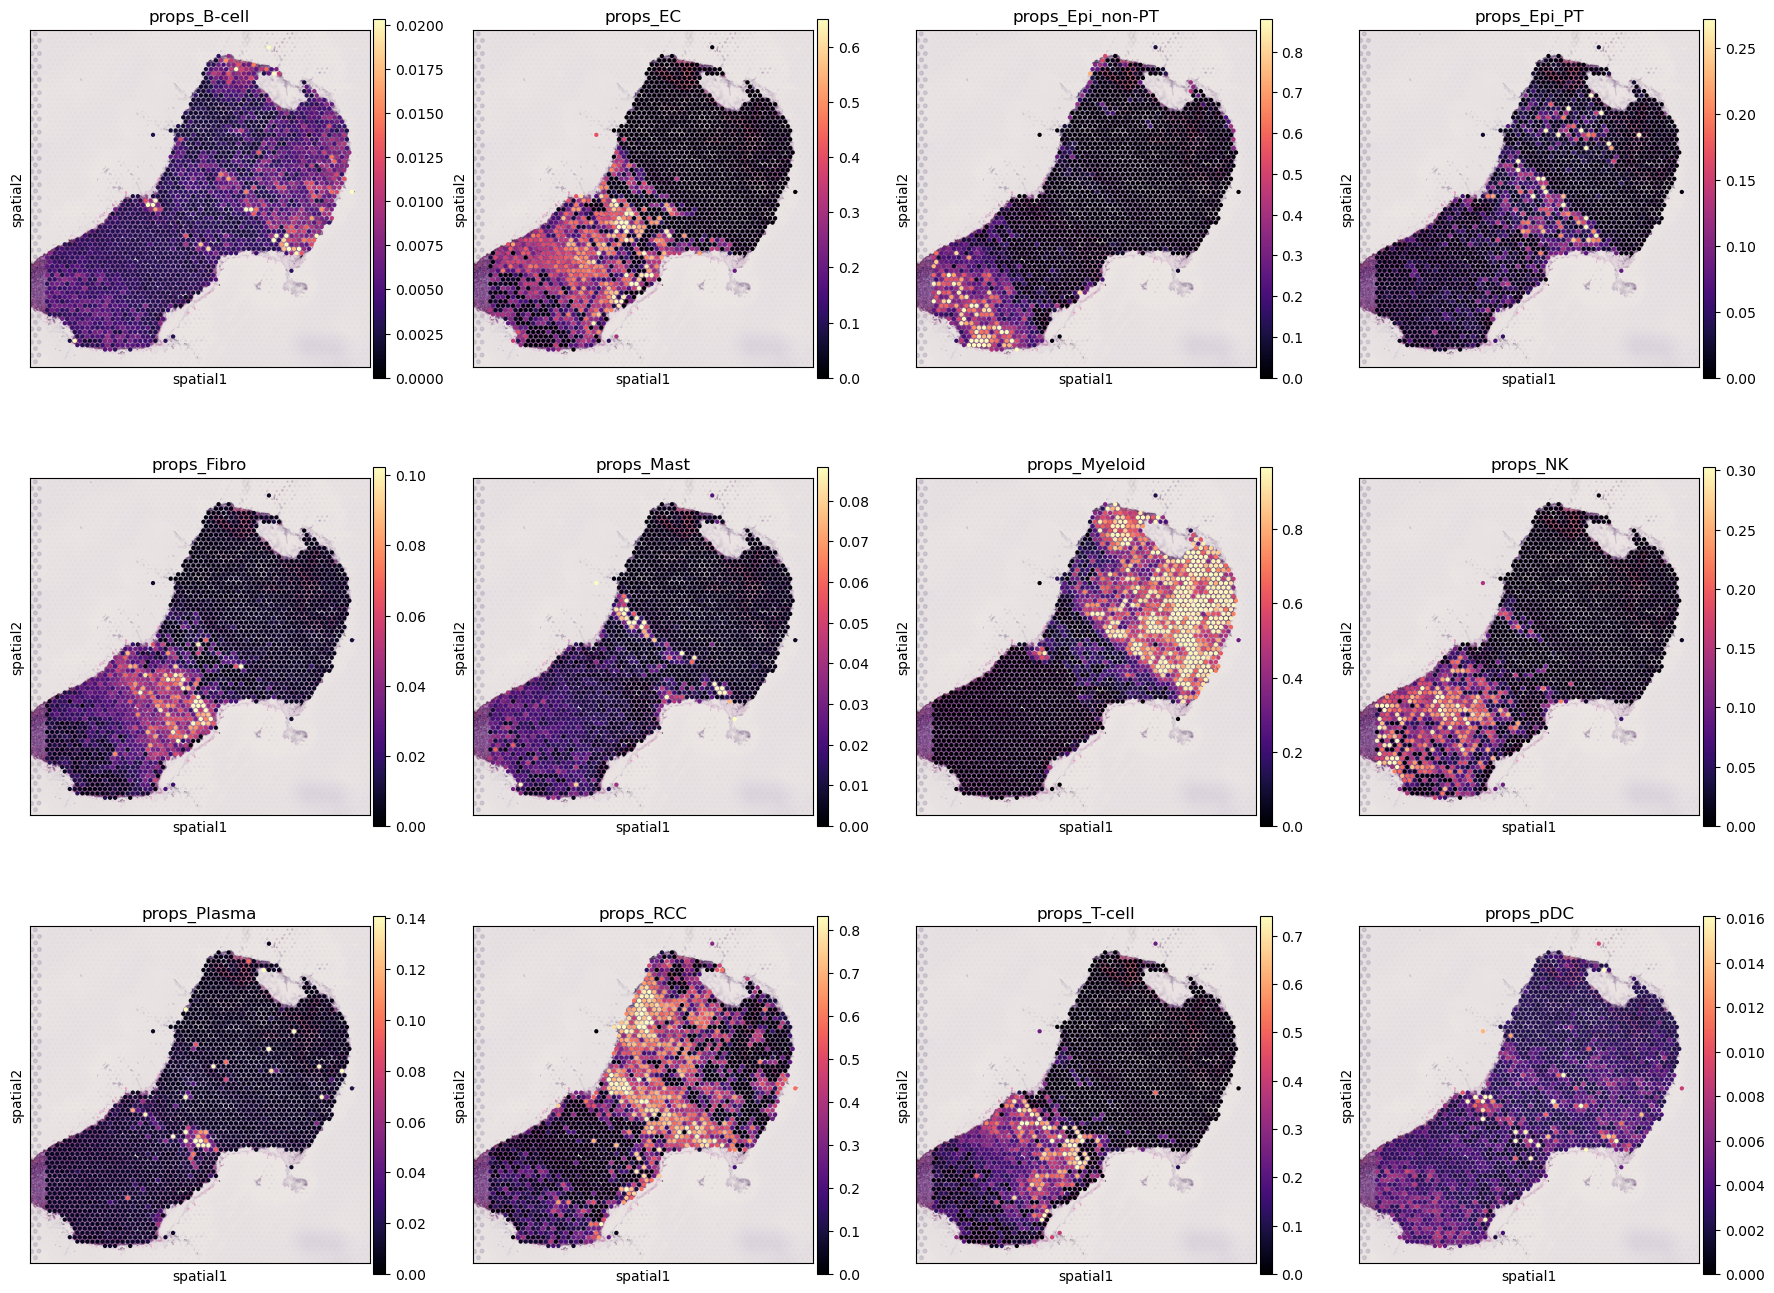

In [49]:
# Visualization of spatial distribution of scRNA-seq data
import matplotlib as mpl

with mpl.rc_context({'axes.facecolor': 'black',
                    'figure.figsize': [4.5, 5]}):
    sc.pl.spatial(adata_st, cmap='magma',
                     # selected cell types
                     color=[f"props_{cell_type}" for cell_type in cell_types],
                     ncols=4, size=1.3,
                     img_key='hires',
                     # limit color scale at 99.2% quantile of cell abundance
                     vmin=0, vmax='p99.2',
                     show=True
                 )

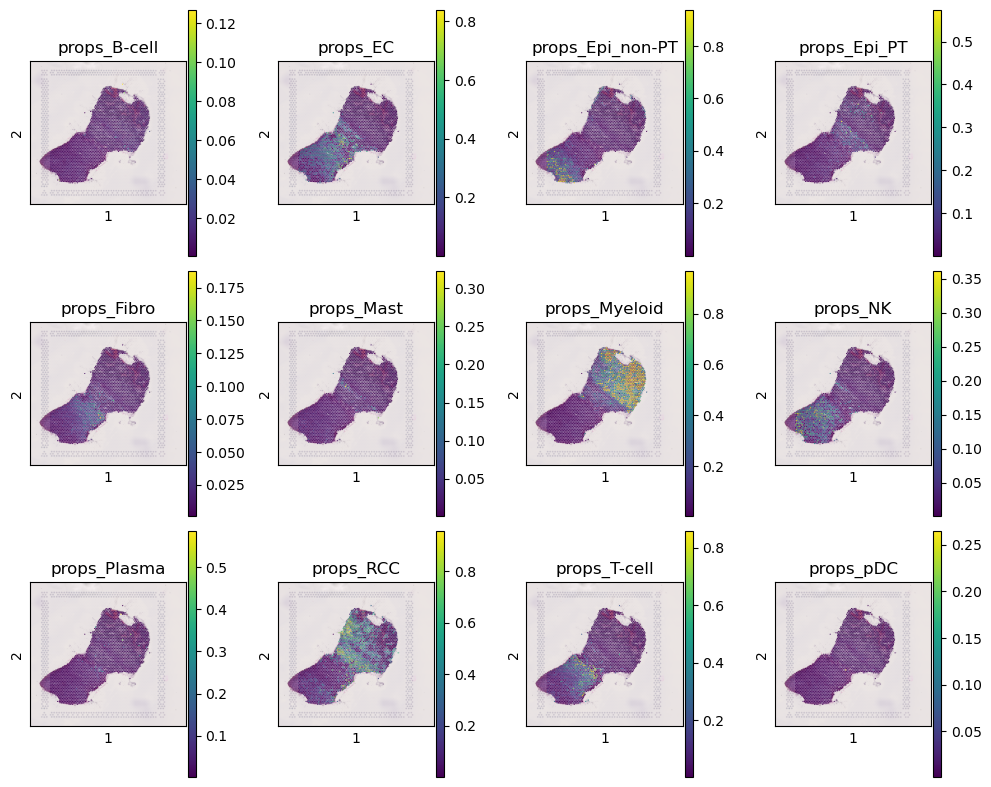

In [50]:
display_cell_proportions(adata_st, cell_types)

In [51]:
gene = "ACE2"

In [52]:
import squidpy as sq

KeyError: 'Could not find key ACE2 in .var_names or .obs.columns.'

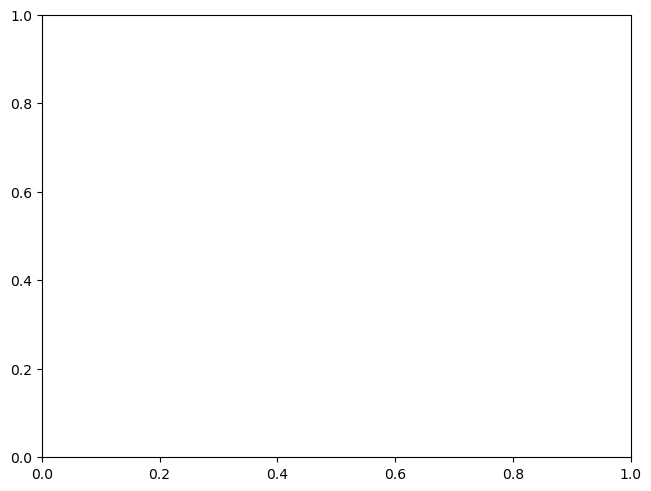

In [53]:
sq.pl.spatial_scatter(adata_st, color=gene, title=f"{gene} (original)" )

In [ ]:
import torch

In [ ]:
torch.softmax(torch.tensor([1.0] * 12), dim=0)

In [ ]:
x = [[[1,2,3,4],
    [5,6,7,8],
    [9,10,11,12]],
    [[13,14,15,16],
    [17,18,19,20],
    [21,22,23,24]]]
x = torch.tensor(x)

In [ ]:
x

In [ ]:
props = [
    [0.5, 0.5, 0],
    [0.2, 0.4, 0.4]
]
props = torch.tensor(props)
props

In [ ]:
props.unsqueeze(-1)

In [ ]:
x.shape

In [ ]:
x.view(-1, x.size(-1))

In [ ]:
y = props.unsqueeze(-1) * x
y

In [ ]:
y.sum(dim=1)

In [ ]:
adata_sc.var['SYMBOL'].unique

In [ ]:
1

In [ ]:
next approach
predict proportions and batch loss e (see spatialscope paper)